In [1]:
# clone YOLOv5 repository
!git clone https://github.com/ultralytics/yolov5  # clone repo
%cd yolov5
!git reset --hard 064365d8683fd002e9ad789c1e91fa3d021b44f0

Cloning into 'yolov5'...
remote: Enumerating objects: 16957, done.
remote: Counting objects: 100% (152/152), done.
remote: Compressing objects: 100% (106/106), done.
remote: Total 16957 (delta 77), reused 98 (delta 46), pack-reused 16805 (from 1)
Receiving objects: 100% (16957/16957), 15.70 MiB | 7.04 MiB/s, done.
Resolving deltas: 100% (11615/11615), done.
/content/yolov5
HEAD is now at 064365d8 Update parse_opt() in export.py to work as in train.py (#10789)


In [2]:
# install dependencies as necessary
!pip install -qr requirements.txt  # install dependencies (ignore errors)
import torch

from IPython.display import Image, clear_output  # to display images
from utils.downloads import attempt_download  # to download models/datasets

# clear_output()
print('Setup complete. Using torch %s %s' % (torch.__version__, torch.cuda.get_device_properties(0) if torch.cuda.is_available() else 'CPU'))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.3/207.3 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 5.6 MB/s eta 0:00:00
Setup complete. Using torch 2.4.0+cu121 _CudaDeviceProperties(name='NVIDIA A100-SXM4-40GB', major=8, minor=0, total_memory=40513MB, multi_processor_count=108)


## Step 6: Download a Dataset

Add your Roboflow API key below to download the default money counting dataset. Alternatively, use the code provided by the Roboflow dashboard in the above step to load a custom dataset.

In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="2ffl1zZqwCdjI4cj61VQ")
project = rf.workspace("work-r9avx").project("sc_3classes")
version = project.version(1)
dataset = version.download("yolov5")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 5.5 MB/s eta 0:00:00
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to SC_3Classes-1 in yolov5pytorch:: 100%|██████████| 3038/3038 [00:00<00:00, 7899.42it/s]


In [ ]:
%cd /content/yolov5

/content/yolov5


In [ ]:
# this is the YAML file Roboflow wrote for us that we're loading into this notebook with our data
%cat {dataset.location}/data.yaml

names:
- acrochordon
- dermatofibro
- lichenoid
nc: 3
roboflow:
  license: CC BY 4.0
  project: sc_3classes
  url: https://universe.roboflow.com/work-r9avx/sc_3classes/dataset/1
  version: 1
  workspace: work-r9avx
test: ../test/images
train: SC_3Classes-1/train/images
val: SC_3Classes-1/valid/images


# Define Model Configuration and Architecture

We will write a yaml script that defines the parameters for our model like the number of classes, anchors, and each layer.

You do not need to edit these cells, but you may.

In [ ]:
# define number of classes based on YAML
import yaml
with open(dataset.location + "/data.yaml", 'r') as stream:
    num_classes = str(yaml.safe_load(stream)['nc'])

In [ ]:
#this is the model configuration we will use for our tutorial
%cat /content/yolov5/models/yolov5l.yaml

# YOLOv5 🚀 by Ultralytics, GPL-3.0 license

# Parameters
nc: 80  # number of classes
depth_multiple: 1.0  # model depth multiple
width_multiple: 1.0  # layer channel multiple
anchors:
  - [10,13, 16,30, 33,23]  # P3/8
  - [30,61, 62,45, 59,119]  # P4/16
  - [116,90, 156,198, 373,326]  # P5/32

# YOLOv5 v6.0 backbone
backbone:
  # [from, number, module, args]
  [[-1, 1, Conv, [64, 6, 2, 2]],  # 0-P1/2
   [-1, 1, Conv, [128, 3, 2]],  # 1-P2/4
   [-1, 3, C3, [128]],
   [-1, 1, Conv, [256, 3, 2]],  # 3-P3/8
   [-1, 6, C3, [256]],
   [-1, 1, Conv, [512, 3, 2]],  # 5-P4/16
   [-1, 9, C3, [512]],
   [-1, 1, Conv, [1024, 3, 2]],  # 7-P5/32
   [-1, 3, C3, [1024]],
   [-1, 1, SPPF, [1024, 5]],  # 9
  ]

# YOLOv5 v6.0 head
head:
  [[-1, 1, Conv, [512, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 6], 1, Concat, [1]],  # cat backbone P4
   [-1, 3, C3, [512, False]],  # 13

   [-1, 1, Conv, [256, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 4], 1, Concat, [1]], 

In [ ]:
#customize iPython writefile so we can write variables
from IPython.core.magic import register_line_cell_magic

@register_line_cell_magic
def writetemplate(line, cell):
    with open(line, 'w') as f:
        f.write(cell.format(**globals()))

In [ ]:
%%writetemplate /content/yolov5/models/custom_yolov5l.yaml

# parameters
nc: {num_classes}  # number of classes
depth_multiple: 0.33  # model depth multiple
width_multiple: 0.50  # layer channel multiple

# anchors
anchors:
  - [10,13, 16,30, 33,23]  # P3/8
  - [30,61, 62,45, 59,119]  # P4/16
  - [116,90, 156,198, 373,326]  # P5/32

# YOLOv5 backbone
backbone:
  # [from, number, module, args]
  [[-1, 1, Focus, [64, 3]],  # 0-P1/2
   [-1, 1, Conv, [128, 3, 2]],  # 1-P2/4
   [-1, 3, BottleneckCSP, [128]],
   [-1, 1, Conv, [256, 3, 2]],  # 3-P3/8
   [-1, 9, BottleneckCSP, [256]],
   [-1, 1, Conv, [512, 3, 2]],  # 5-P4/16
   [-1, 9, BottleneckCSP, [512]],
   [-1, 1, Conv, [1024, 3, 2]],  # 7-P5/32
   [-1, 1, SPP, [1024, [5, 9, 13]]],
   [-1, 3, BottleneckCSP, [1024, False]],  # 9
  ]

# YOLOv5 head
head:
  [[-1, 1, Conv, [512, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 6], 1, Concat, [1]],  # cat backbone P4
   [-1, 3, BottleneckCSP, [512, False]],  # 13

   [-1, 1, Conv, [256, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 4], 1, Concat, [1]],  # cat backbone P3
   [-1, 3, BottleneckCSP, [256, False]],  # 17 (P3/8-small)

   [-1, 1, Conv, [256, 3, 2]],
   [[-1, 14], 1, Concat, [1]],  # cat head P4
   [-1, 3, BottleneckCSP, [512, False]],  # 20 (P4/16-medium)

   [-1, 1, Conv, [512, 3, 2]],
   [[-1, 10], 1, Concat, [1]],  # cat head P5
   [-1, 3, BottleneckCSP, [1024, False]],  # 23 (P5/32-large)

   [[17, 20, 23], 1, Detect, [nc, anchors]],  # Detect(P3, P4, P5)
  ]

# Train Custom YOLOv5 Detector

### Next, we'll fire off training!


Here, we are able to pass a number of arguments:
- **img:** define input image size
- **batch:** determine batch size
- **epochs:** define the number of training epochs. (Note: often, 3000+ are common here!)
- **data:** set the path to our yaml file
- **cfg:** specify our model configuration
- **weights:** specify a custom path to weights. (Note: you can download weights from the Ultralytics Google Drive [folder](https://drive.google.com/open?id=1Drs_Aiu7xx6S-ix95f9kNsA6ueKRpN2J))
- **name:** result names
- **nosave:** only save the final checkpoint
- **cache:** cache images for faster training

In [ ]:
# train yolov5s on custom data for 100 epochs
# time its performance
%%time
%cd /content/yolov5/
!python train.py --img 640 --batch 16 --epochs 600 --data {dataset.location}/data.yaml --cfg ./models/custom_yolov5l.yaml --weights '' --name yolov5s_results  --cache

Streaming output truncated to the last 5000 lines.
    504/599      4.57G     0.0265    0.01529   0.001198         46        640:  18% 12/67 [00:01<00:04, 11.88it/s]/content/yolov5/train.py:308: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
    504/599      4.57G    0.02642    0.01494   0.001197         40        640:  18% 12/67 [00:01<00:04, 11.88it/s]/content/yolov5/train.py:308: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
    504/599      4.57G    0.02688    0.01512   0.001222         50        640:  21% 14/67 [00:01<00:04, 11.28it/s]/content/yolov5/train.py:308: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
    504/599      4.57G    0.02694    

# Evaluate Custom YOLOv5 Detector Performance

You can view the training graphs associated with a training job in the `/content/yolov5/runs/train/yolov5s_results/results.png` folder.

Training losses and performance metrics are also saved to Tensorboard and also to a logfile defined above with the **--name** flag when we train. In our case, we named this `yolov5s_results`.

Note from Glenn: Partially completed `results.txt` files can be plotted with `from utils.utils import plot_results; plot_results()`.

In [ ]:
from PIL import Image
from utils.plots import plot_results  # plot results.txt as results.png
Image.open('/content/yolov5/runs/train/yolov5s_results/results.png').show()  # view results.png

### Curious? Visualize Our Training Data with Labels

After training starts, view `train*.jpg` images to see training images, labels and augmentation effects.

Note a mosaic dataloader is used for training (shown below), a new dataloading concept developed by Glenn Jocher and first featured in [YOLOv4](https://arxiv.org/abs/2004.10934).

In [ ]:
from PIL import Image

# Open the image using Image.open()
image = Image.open('/content/yolov5/runs/train/yolov5s_results/val_batch0_labels.jpg')

# Resize the image using the resize() method
image = image.resize((900, image.size[1]))

# Now you can work with the 'image' object, for example, display it
image.show()

In [5]:
!python val.py --weights /content/best.pt --data /content/yolov5/SC_3Classes-1/data.yaml --conf 0.001

val: data=/content/yolov5/SC_3Classes-1/data.yaml, weights=['/content/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-72-g064365d8 Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov5/models/experimental.py:79: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during un

In [6]:
!zip -r /content/yolov5/runs/valV5wli.zip /content/yolov5/runs/val
from google.colab import files
files.download("/content/yolov5/runs/valV5wli.zip")

  adding: content/yolov5/runs/val/ (stored 0%)
  adding: content/yolov5/runs/val/exp/ (stored 0%)
  adding: content/yolov5/runs/val/exp/PR_curve.png (deflated 12%)
  adding: content/yolov5/runs/val/exp/confusion_matrix.png (deflated 26%)
  adding: content/yolov5/runs/val/exp/R_curve.png (deflated 10%)
  adding: content/yolov5/runs/val/exp/P_curve.png (deflated 9%)
  adding: content/yolov5/runs/val/exp/F1_curve.png (deflated 10%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# print out an augmented training example
print("GROUND TRUTH AUGMENTED TRAINING DATA:")
from PIL import Image
Image.open('/content/yolov5/runs/train/yolov5s_results/train_batch0.jpg').show() # Call

GROUND TRUTH AUGMENTED TRAINING DATA:


# Run Inference With Trained Weights

Next, we can run inference with a pretrained checkpoint on all images in the `test/images` folder to understand how our model performs on our test set.

In [ ]:
# trained weights are saved by default in our weights folder
%ls runs/

train/


In [ ]:
%ls runs/train/yolov5s_results/weights

best.pt  last.pt


In the snippet below, replace `Cash-Counter-10` with the name of the folder in which your dataset is stored.

In [ ]:
%cd /content/yolov5/
!python detect.py --weights runs/train/yolov5s_results/weights/best.pt --img 416 --conf 0.4 --source /content/yolov5/SC_3Classes-1/test/images/

/content/yolov5
detect: weights=['runs/train/yolov5s_results/weights/best.pt'], source=/content/yolov5/SC_3Classes-1/test/images/, data=data/coco128.yaml, imgsz=[416, 416], conf_thres=0.4, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-72-g064365d8 Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov5/models/experimental.py:79: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for

In [ ]:
%cd /content/yolov5/
!python detect.py --weights runs/train/yolov5s_results/weights/best.pt --img 416 --conf 0.4 --source /content/yolov5/SC_3Classes-1/test/images/ --save-txt --save-conf

/content/yolov5
detect: weights=['runs/train/yolov5s_results/weights/best.pt'], source=/content/yolov5/SC_3Classes-1/test/images/, data=data/coco128.yaml, imgsz=[416, 416], conf_thres=0.4, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-72-g064365d8 Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov5/models/experimental.py:79: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for m

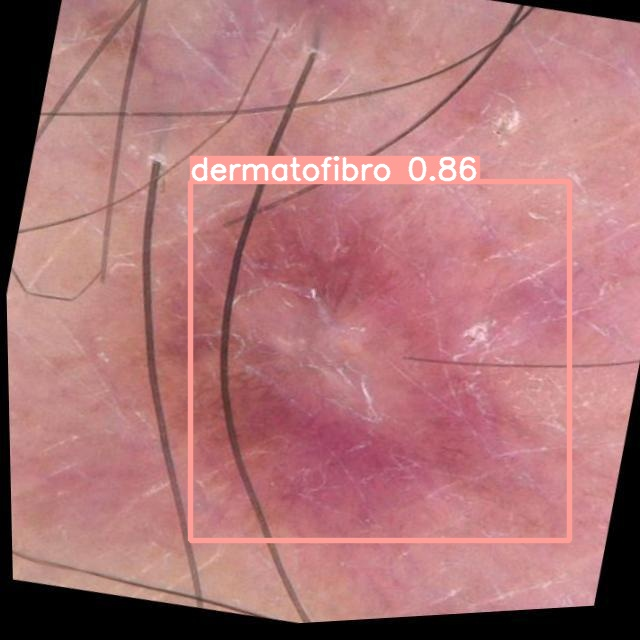

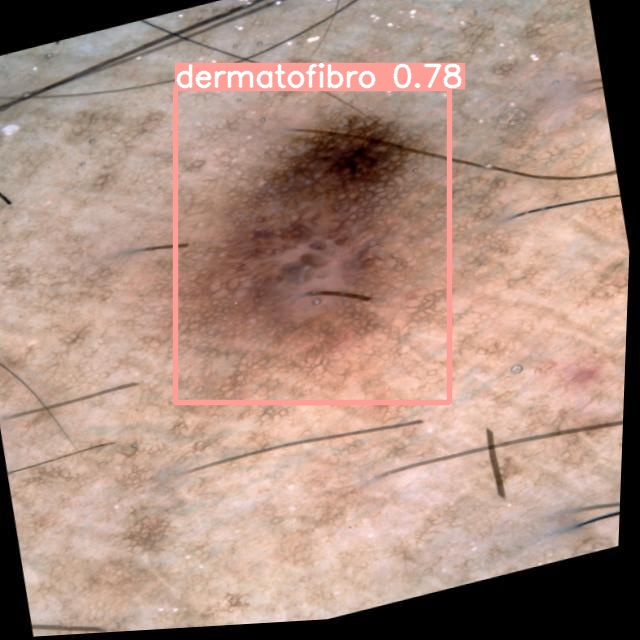

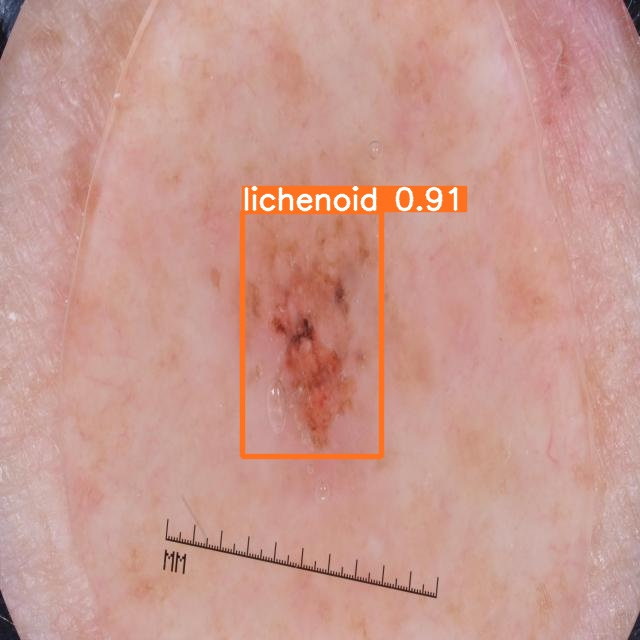

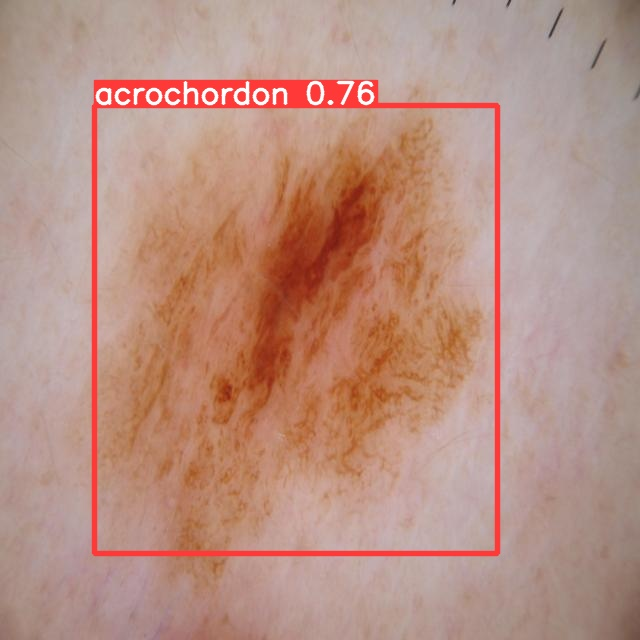

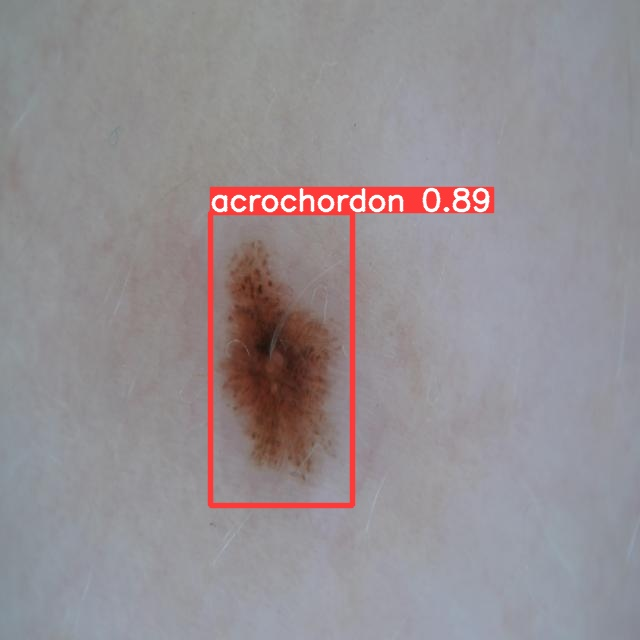

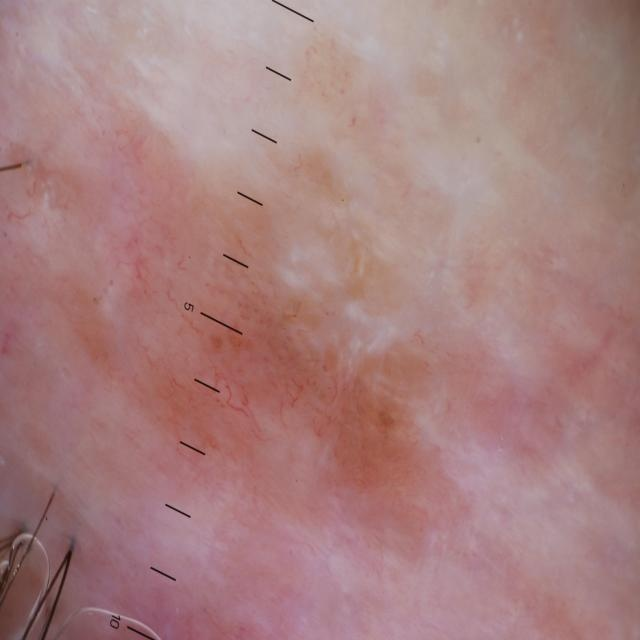

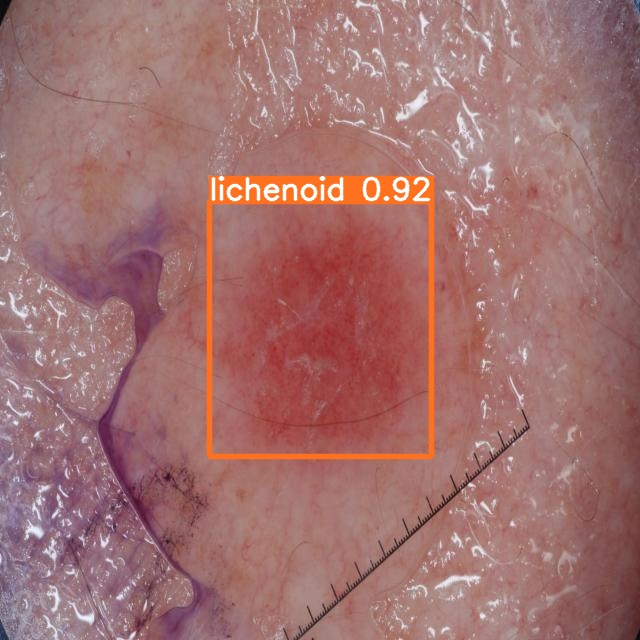

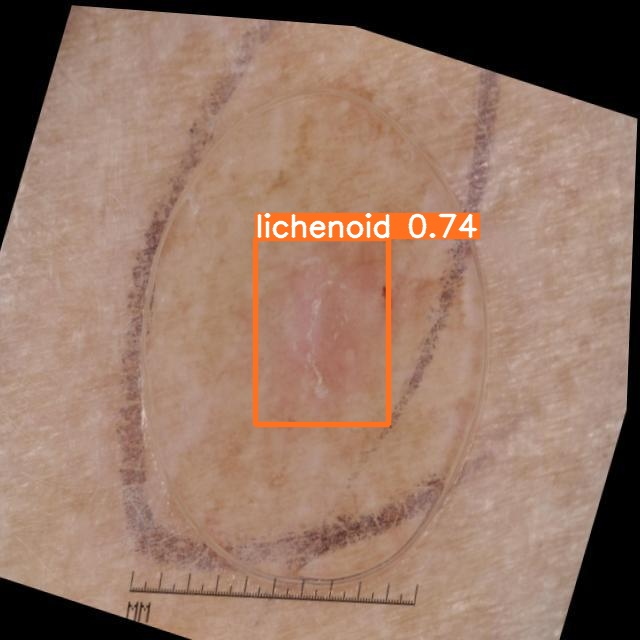

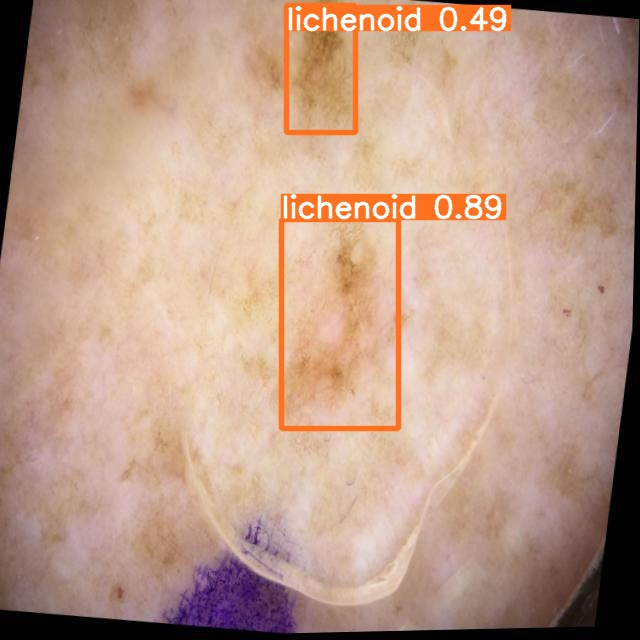

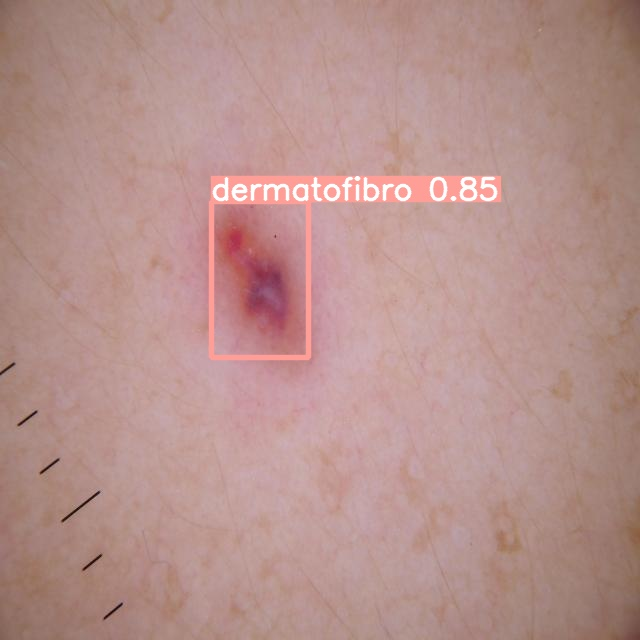

In [ ]:
import glob
from IPython.display import Image, display

for imageName in glob.glob('/content/yolov5/runs/detect/exp2/*.jpg')[:10]: #assuming JPG
    display(Image(filename=imageName))

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Path to ground truth and predictions (adjust paths)
ground_truth_path = '/content/yolov5/SC_3Classes-1/test/labels'
predictions_path = '/content/yolov5/runs/detect/exp2/labels'

class_names = ['acrochordon', 'dermatofibro', 'lichenoid']  # Your 3 classes
output_image_path = '/content/yolov5/runs/confusion_matrixBack.png'  # Save path for confusion matrix

# Initialize lists to store labels
ground_truth_labels = []
predicted_labels = []

# Function to read labels from txt files
def read_labels(file_path):
    labels = []
    with open(file_path, 'r') as f:
        for line in f:
            label = int(line.split()[0])  # Class ID is the first element
            labels.append(label)
    return labels

# Loop through ground truth files
for filename in os.listdir(ground_truth_path):
    if filename.endswith('.txt'):
        # Read ground truth labels
        gt_labels = read_labels(os.path.join(ground_truth_path, filename))

        # Read predicted labels (if available)
        pred_file = os.path.join(predictions_path, filename)
        if os.path.exists(pred_file):
            pred_labels = read_labels(pred_file)
            # Ensure both lists have the same length for comparison
            if len(gt_labels) == len(pred_labels):
                ground_truth_labels.extend(gt_labels)
                predicted_labels.extend(pred_labels)
            else:
                # Handle cases with mismatched lengths (e.g., add -1 or skip)
                print(f"Mismatched lengths for {filename}: Ground truth - {len(gt_labels)}, Predictions - {len(pred_labels)}")
                continue

        else:
            print(f"No prediction file found for {filename}")
            continue

# Compute the confusion matrix
cm = confusion_matrix(ground_truth_labels, predicted_labels, labels=[0, 1, 2])

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for YOLOv5 Inference')

# Save the confusion matrix image
plt.savefig(output_image_path)
print(f"Confusion matrix saved to {output_image_path}")

# Show the confusion matrix
plt.show()


Mismatched lengths for ISIC_0014343_JPG_jpg.rf.16c4141ced5f79ecb155d6bd4ddff809.txt: Ground truth - 1, Predictions - 2
Mismatched lengths for ISIC_0021248_JPG_jpg.rf.30ab14bbcfacdf09e02a2bdbe9c3d5e1.txt: Ground truth - 4, Predictions - 3
No prediction file found for ISIC_0022855_JPG_jpg.rf.fbc86ab6dd8429598caed79c24f99609.txt
Mismatched lengths for ISIC_0021868_JPG_jpg.rf.5ce4a0fa93669212a2824d0cc64a2053.txt: Ground truth - 4, Predictions - 1
Mismatched lengths for ISIC_0023169_JPG_jpg.rf.742f7b6f80c3eaa9fc35e3141b559edb.txt: Ground truth - 4, Predictions - 3
Mismatched lengths for ISIC_6596403_JPG_jpg.rf.210e2f4746887a6116e69bd164c16e64.txt: Ground truth - 1, Predictions - 2
Mismatched lengths for ISIC_0022690_JPG_jpg.rf.c4c90f552744e3714fcb5f4efc270d2b.txt: Ground truth - 2, Predictions - 1
Mismatched lengths for ISIC_0012087_JPG_jpg.rf.7c188c4fa2d59f7bb37389887fff03b9.txt: Ground truth - 2, Predictions - 1
Mismatched lengths for ISIC_0022521_JPG_jpg.rf.4c985ff138b24f03e80d7825b1322a

In [ ]:
# Function to calculate precision and recall using True Positives, False Positives, and False Negatives
def calculate_precision_recall(TP, FP, FN):
    # Precision calculation
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    # Recall calculation
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    return precision, recall

# Values for each class
classes = {
    "Acrochordon": {"TP": 13, "FP": 3, "FN": 1},
    "Dermatofibro": {"TP": 56, "FP": 4, "FN": 4},
    "Lichenoid": {"TP": 33, "FP": 3, "FN": 5}
}

# Calculate and print precision and recall for each class
for class_name, values in classes.items():
    precision, recall = calculate_precision_recall(values['TP'], values['FP'], values['FN'])
    print(f"{class_name}: Precision = {precision:.2f}, Recall = {recall:.2f}")


Acrochordon: Precision = 0.81, Recall = 0.93
Dermatofibro: Precision = 0.93, Recall = 0.93
Lichenoid: Precision = 0.92, Recall = 0.87


In [ ]:
!zip -r /content/yolov5/runsV5WLI.zip /content/yolov5/runs
from google.colab import files
files.download("/content/yolov5/runsV5WLI.zip")

  adding: content/yolov5/runs/ (stored 0%)
  adding: content/yolov5/runs/train/ (stored 0%)
  adding: content/yolov5/runs/train/yolov5s_results/ (stored 0%)
  adding: content/yolov5/runs/train/yolov5s_results/hyp.yaml (deflated 45%)
  adding: content/yolov5/runs/train/yolov5s_results/val_batch1_pred.jpg (deflated 11%)
  adding: content/yolov5/runs/train/yolov5s_results/opt.yaml (deflated 49%)
  adding: content/yolov5/runs/train/yolov5s_results/events.out.tfevents.1726059403.5ea69181bd3b.867.0 (deflated 40%)
  adding: content/yolov5/runs/train/yolov5s_results/P_curve.png (deflated 8%)
  adding: content/yolov5/runs/train/yolov5s_results/val_batch1_labels.jpg (deflated 11%)
  adding: content/yolov5/runs/train/yolov5s_results/val_batch2_pred.jpg (deflated 9%)
  adding: content/yolov5/runs/train/yolov5s_results/val_batch0_pred.jpg (deflated 10%)
  adding: content/yolov5/runs/train/yolov5s_results/weights/ (stored 0%)
  adding: content/yolov5/runs/train/yolov5s_results/weights/best.pt (defla

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Deploy Model on Roboflow

Once you have finished training your YOLOv5 model, you’ll have a set of trained weights ready for use. These weights will be in the `/content/yolov5/runs/train/yolov5s_results/` folder of your project. You can upload your model weights to Roboflow Deploy to use your trained weights on our infinitely scalable infrastructure.

The `.deploy()` function in the [Roboflow pip package](https://docs.roboflow.com/python) now supports uploading YOLOv5 weights.

**Before you run this code, make sure you create a new Version in the Roboflow dashboard following the instructions we covered earlier. Fill in your project name, workspace, and version number below.**

To upload model weights, add the following code to the “Inference with Custom Model” section in the aforementioned notebook:

In [ ]:
rf = Roboflow(api_key="YOUR_API_KEY")
project = rf.workspace("workspace").project("project")
dataset = project.version(1)

project.version(dataset.version).deploy(model_type="yolov5", model_path=f"/content/yolov5/runs/train/yolov5s_results/")

In [ ]:
#Run inference on your model on a persistant, auto-scaling, cloud API

#load model
model = project.version(dataset.version).model

#choose random test set image
import os, random
test_set_loc = dataset.location + "/test/images/"
random_test_image = random.choice(os.listdir(test_set_loc))
print("running inference on " + random_test_image)

pred = model.predict(test_set_loc + random_test_image, confidence=40, overlap=30).json()
pred

# Deploy Your Model to the Edge

In addition to using the Roboflow hosted API for deployment, you can use [Roboflow Inference](https://inference.roboflow.com), an open source inference solution that has powered millions of API calls in production environments. Inference works with CPU and GPU, giving you immediate access to a range of devices, from the NVIDIA Jetson to TRT-compatible devices to ARM CPU devices.

With Roboflow Inference, you can self-host and deploy your model on-device. You can deploy applications using the [Inference Docker containers](https://inference.roboflow.com/quickstart/docker/) or the pip package.

For example, to install Inference on a device with an NVIDIA GPU, we can use:

```
docker pull roboflow/roboflow-inference-server-gpu
```

Then we can run inference via HTTP:

```python
import requests

workspace_id = ""
model_id = ""
image_url = ""
confidence = 0.75
api_key = ""
iou_threshold = 0.5

infer_payload = {
    "image": {
        "type": "url",
        "value": image_url,
    },
    "confidence": confidence,
    "iou_threshold": iou_threshold,
    "api_key": api_key,
}
res = requests.post(
    f"http://localhost:9001/{workspace_id}/{model_id}",
    json=infer_object_detection_payload,
)

predictions = res.json()
```

Above, set your Roboflow workspace ID, model ID, and API key.

- [Find your workspace and model ID](https://docs.roboflow.com/api-reference/workspace-and-project-ids?ref=blog.roboflow.com)
- [Find your API key](https://docs.roboflow.com/api-reference/authentication?ref=blog.roboflow.com#retrieve-an-api-key)

Also, set the URL of an image on which you want to run inference. This can be a local file.

_To use your YOLOv5 model commercially with Inference, you will need a Roboflow Enterprise license, through which you gain a pass-through license for using YOLOv5. An enterprise license also grants you access to features like advanced device management, multi-model containers, auto-batch inference, and more._

## 🏆 Congratulations

### Learning Resources

Roboflow has produced many resources that you may find interesting as you advance your knowledge of computer vision:

- [Roboflow Notebooks](https://github.com/roboflow/notebooks): A repository of over 20 notebooks that walk through how to train custom models with a range of model types, from YOLOv7 to SegFormer.
- [Roboflow YouTube](https://www.youtube.com/c/Roboflow): Our library of videos featuring deep dives into the latest in computer vision, detailed tutorials that accompany our notebooks, and more.
- [Roboflow Discuss](https://discuss.roboflow.com/): Have a question about how to do something on Roboflow? Ask your question on our discussion forum.
- [Roboflow Models](https://roboflow.com): Learn about state-of-the-art models and their performance. Find links and tutorials to guide your learning.

### Convert data formats

Roboflow provides free utilities to convert data between dozens of popular computer vision formats. Check out [Roboflow Formats](https://roboflow.com/formats) to find tutorials on how to convert data between formats in a few clicks.

### Connect computer vision to your project logic

[Roboflow Templates](https://roboflow.com/templates) is a public gallery of code snippets that you can use to connect computer vision to your project logic. Code snippets range from sending emails after inference to measuring object distance between detections.